# 1. Análise exploratória dos dados

Reconhecimento de comandos de voz em português com MFCC, KNN e SVM (Machine Learning).

Este notebook descreve o conjunto de dados antes do treinamento: quem são os participantes
(sexo e idade), quantas gravações há por comando, a duração dos áudios, as falas fora do
escopo do Common Voice e a divisão em treino, validação e teste. No fim, mostra como um
áudio vira MFCC.

**Entrada:** `dados/metadata.csv` e `dados/audios/` (gerados por `voice_data_processing.ipynb`). Se existir, `saida/divisao.csv` (gerado pelo baseline ou pelo
notebook de teste ml) é usado para a tabela de partições.

Só gráficos agregados: nenhum dado individual de participante é exibido.

In [1]:
!pip install -q librosa soundfile pandas matplotlib

In [2]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/Projetos/Deteccao_Vozes/dados.zip -d /content

Mounted at /content/drive


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display

META = "dados/metadata.csv"
AUDIO_DIR = "dados/audios"
DIVISAO = "saida/divisao.csv"
FIG = "figuras"
os.makedirs(FIG, exist_ok=True)

# Estilo
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
})
COR, COR2 = "0.35", "0.7"

def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nome}.png", bbox_inches="tight")
    plt.show()

meta = pd.read_csv(META)
cmd = meta[meta["tipo"] == "comando"].copy()
neg = meta[meta["tipo"] == "negativo"].copy()

# Uma linha por participante do grupo (sexo e idade se repetem em cada gravação)
part = cmd.groupby("locutor").agg(sexo=("sexo", "first"), idade=("idade", "first"),
                                  gravacoes=("arquivo", "size")).reset_index()
print(f"Participantes: {len(part)} | gravações de comandos: {len(cmd)} | "
      f"falas fora do escopo: {len(neg)} de {neg['locutor'].nunique()} locutores")

Participantes: 43 | gravações de comandos: 516 | falas fora do escopo: 519 de 202 locutores


## 1.1 Resumo do conjunto

In [5]:
resumo = pd.DataFrame({
    "Itens": ["Participantes do grupo", "Gravações de comandos", "Comandos distintos",
              "Repetições por comando", "Falas fora do escopo (Common Voice)",
              "Locutores do Common Voice"],
    "Valor": [len(part), len(cmd), cmd["rotulo"].nunique(),
              int(cmd["repeticao"].max()) if "repeticao" in cmd and len(cmd) else 0,
              len(neg), neg["locutor"].nunique()],
})
resumo

,Itens,Valor
0,Participantes do grupo,43
1,Gravações de comandos,516
2,Comandos distintos,6
3,Repetições por comando,2
4,Falas fora do escopo (Common Voice),519
5,Locutores do Common Voice,202


## 1.2 Distribuição por sexo

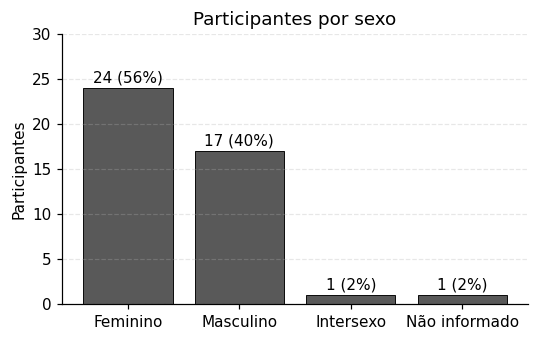

In [6]:
nomes_sexo = {"feminino": "Feminino", "masculino": "Masculino",
              "intersexo": "Intersexo", "nao_informado": "Não informado"}
cont = part["sexo"].map(nomes_sexo).fillna("Não informado").value_counts()

fig, ax = plt.subplots(figsize=(5, 3.2))
barras = ax.bar(cont.index, cont.values, color=COR, edgecolor="black", linewidth=0.6)
ax.bar_label(barras, labels=[f"{v} ({v / cont.sum():.0%})" for v in cont.values], padding=2)
ax.set_ylabel("Participantes")
ax.set_title("Participantes por sexo")
ax.set_ylim(0, cont.max() * 1.25)
ax.grid(axis="x", visible=False)
salvar("sexo")

## 1.3 Distribuição de idade

Idade: média 41.5 | mediana 46 | mín. 12 | máx. 73 anos


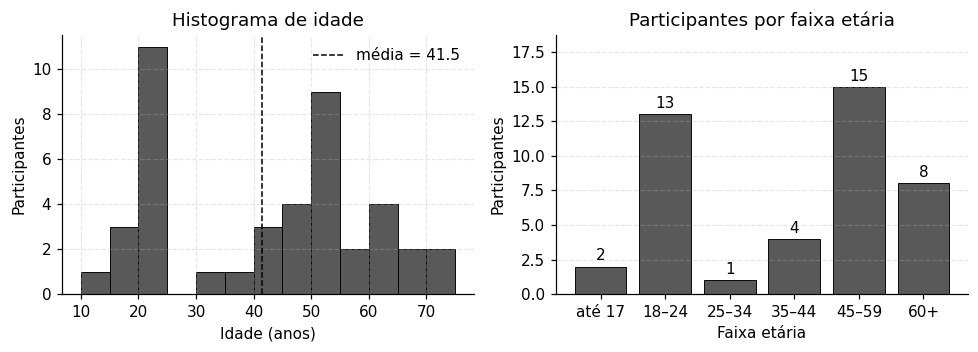

In [7]:
idades = part["idade"].dropna()
print(f"Idade: média {idades.mean():.1f} | mediana {idades.median():.0f} | "
      f"mín. {idades.min():.0f} | máx. {idades.max():.0f} anos")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))

# Histograma com intervalos de 5 anos
lim_inf = int(idades.min() // 5 * 5)
lim_sup = int(idades.max() // 5 * 5 + 10)
axs[0].hist(idades, bins=range(lim_inf, lim_sup, 5), color=COR, edgecolor="black", linewidth=0.6)
axs[0].axvline(idades.mean(), color="black", linestyle="--", linewidth=1,
               label=f"média = {idades.mean():.1f}")
axs[0].set_xlabel("Idade (anos)"); axs[0].set_ylabel("Participantes")
axs[0].set_title("Histograma de idade"); axs[0].legend(frameon=False)

# Faixas etárias
faixas = pd.cut(idades, bins=[0, 17, 24, 34, 44, 59, 120],
                labels=["até 17", "18–24", "25–34", "35–44", "45–59", "60+"])
cf = faixas.value_counts().sort_index()
b = axs[1].bar(cf.index.astype(str), cf.values, color=COR, edgecolor="black", linewidth=0.6)
axs[1].bar_label(b, padding=2)
axs[1].set_xlabel("Faixa etária"); axs[1].set_ylabel("Participantes")
axs[1].set_title("Participantes por faixa etária")
axs[1].set_ylim(0, max(cf.max(), 1) * 1.25); axs[1].grid(axis="x", visible=False)
salvar("idade")

## 1.4 Idade por sexo

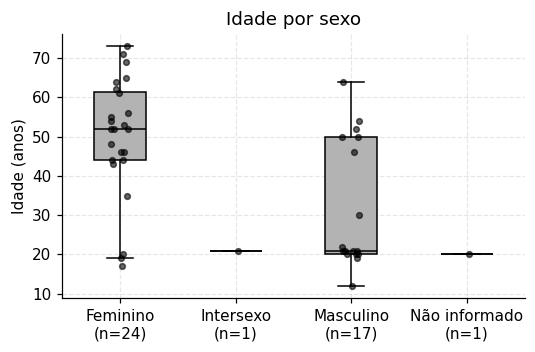

In [8]:
grupos = [(nomes_sexo.get(s, s), g["idade"].dropna().values)
          for s, g in part.groupby("sexo") if g["idade"].notna().any()]

fig, ax = plt.subplots(figsize=(5, 3.3))
ax.boxplot([g for _, g in grupos], tick_labels=[f"{n}\n(n={len(g)})" for n, g in grupos],
           patch_artist=True, showfliers=False, boxprops=dict(facecolor=COR2), medianprops=dict(color="black"))
for i, (_, g) in enumerate(grupos, start=1):     # pontos individuais sobre a caixa
    ax.scatter(np.full(len(g), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(g)),
               g, s=14, color="black", alpha=0.6, zorder=3)
ax.set_ylabel("Idade (anos)"); ax.set_title("Idade por sexo")
salvar("idade_por_sexo")

## 1.5 Gravações por comando

Cada participante grava cada comando duas vezes, então as classes devem ficar equilibradas.
Diferenças aqui indicam gravações perdidas ou incompletas.

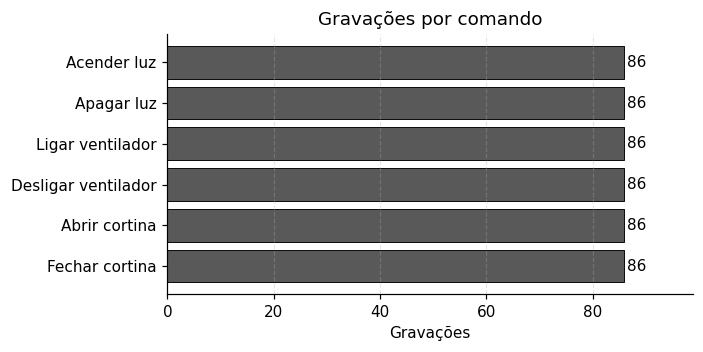

Participantes com as 12 gravações completas: 43 de 43


In [9]:
ordem = ["acender_luz", "apagar_luz", "ligar_ventilador",
         "desligar_ventilador", "abrir_cortina", "fechar_cortina"]
cc = cmd["rotulo"].value_counts().reindex([o for o in ordem if o in cmd["rotulo"].unique()])
rotulos_bonitos = [r.replace("_", " ").capitalize() for r in cc.index]

fig, ax = plt.subplots(figsize=(6.5, 3.3))
b = ax.barh(rotulos_bonitos[::-1], cc.values[::-1], color=COR, edgecolor="black", linewidth=0.6)
ax.bar_label(b, padding=2)
ax.set_xlabel("Gravações"); ax.set_title("Gravações por comando")
ax.set_xlim(0, cc.max() * 1.15); ax.grid(axis="y", visible=False)
salvar("gravacoes_por_comando")

completos = (part["gravacoes"] == len(ordem) * 2).sum()
print(f"Participantes com as {len(ordem) * 2} gravações completas: {completos} de {len(part)}")

## 1.6 Duração das gravações

A duração vem do site de coleta (`duracao_ms`) e inclui o silêncio antes e depois da fala.
No pré-processamento, o silêncio das pontas é removido e todo áudio é ajustado para 2 s.

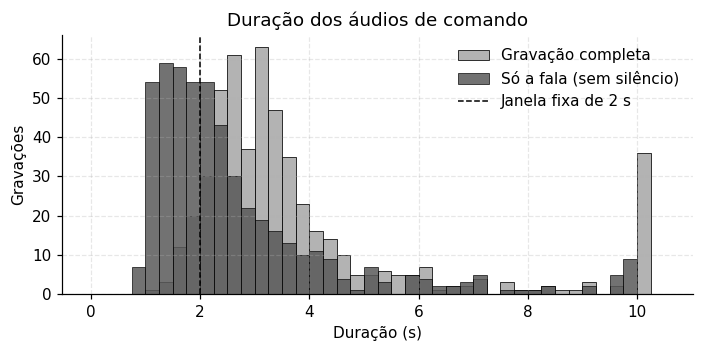

Fala sem silêncio: mediana 2.10 s | 55% das falas passam de 2 s e serão cortadas


In [10]:
dur = cmd["duracao_ms"].dropna() / 1000

# Duração da fala depois de remover o silêncio (mesmo critério do pré-processamento)
def duracao_fala(arq):
    y, sr = librosa.load(os.path.join(AUDIO_DIR, arq), sr=16000, mono=True)
    yt, _ = librosa.effects.trim(y, top_db=30)
    return len(yt) / sr
fala = cmd["arquivo"].apply(duracao_fala)

fig, ax = plt.subplots(figsize=(6.5, 3.3))
bins = np.arange(0, max(dur.max(), fala.max()) + 0.5, 0.25)
ax.hist(dur, bins=bins, color=COR2, edgecolor="black", linewidth=0.5, label="Gravação completa")
ax.hist(fala, bins=bins, color=COR, edgecolor="black", linewidth=0.5, alpha=0.85,
        label="Só a fala (sem silêncio)")
ax.axvline(2.0, color="black", linestyle="--", linewidth=1, label="Janela fixa de 2 s")
ax.set_xlabel("Duração (s)"); ax.set_ylabel("Gravações")
ax.set_title("Duração dos áudios de comando"); ax.legend(frameon=False)
salvar("duracao")

print(f"Fala sem silêncio: mediana {fala.median():.2f} s | "
      f"{(fala > 2).mean():.0%} das falas passam de 2 s e serão cortadas")

## 1.7 Falas fora do escopo (Common Voice)

Os clipes foram sorteados com no máximo 3 por locutor e sem palavras dos comandos, para que
a classe "fora" não seja dominada por poucas vozes.

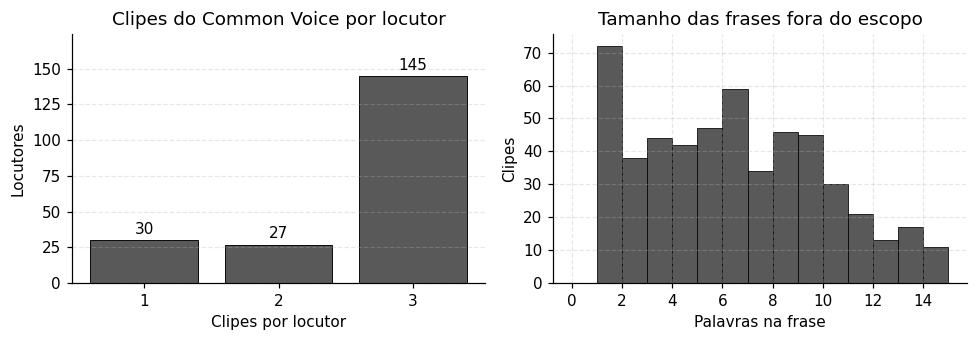

Exemplos de frases fora do escopo:
  - Amílcar Cabral
  - Cascú é um casco.
  - Símon Bolívar
  - Santarém Novo
  - estanho, antimônio, telúrio, iodo, xenônio, césio, bário, lutécio, háfnio, tântalo, tungstênio, rênio, ósmio, irídio


In [11]:
if len(neg):
    por_loc = neg["locutor"].value_counts().value_counts().sort_index()
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
    b = axs[0].bar(por_loc.index.astype(str), por_loc.values, color=COR, edgecolor="black", linewidth=0.6)
    axs[0].bar_label(b, padding=2)
    axs[0].set_xlabel("Clipes por locutor"); axs[0].set_ylabel("Locutores")
    axs[0].set_title("Clipes do Common Voice por locutor")
    axs[0].set_ylim(0, por_loc.max() * 1.2); axs[0].grid(axis="x", visible=False)

    if "texto" in neg:
        palavras = neg["texto"].dropna().str.split().str.len()
        axs[1].hist(palavras, bins=range(0, int(palavras.max()) + 2), color=COR,
                    edgecolor="black", linewidth=0.5)
        axs[1].set_xlabel("Palavras na frase"); axs[1].set_ylabel("Clipes")
        axs[1].set_title("Tamanho das frases fora do escopo")
    salvar("common_voice")
    if "texto" in neg:
        print("Exemplos de frases fora do escopo:")
        for t in neg["texto"].dropna().sample(min(5, len(neg)), random_state=0):
            print("  -", t)

## 1.8 Divisão em treino, validação e teste

A divisão é feita por locutor: as gravações de uma pessoa ficam todas na mesma partição.
É a mesma divisão usada no trabalho de redes neurais.

audios          locutores         
tipo     comando negativo   comando negativo
particao                                    
treino       312      322        26      121
val           96       93         8       41
teste        108      104         9       40

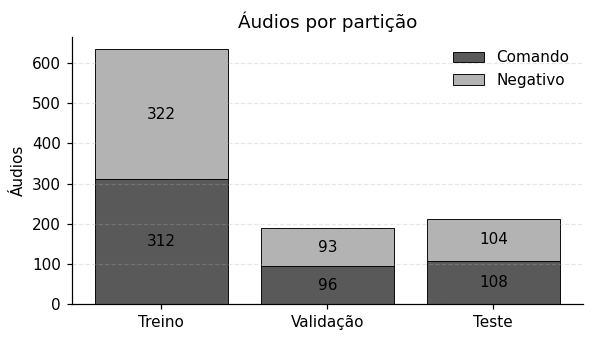

In [14]:
if os.path.exists(DIVISAO):
    div = pd.read_csv(DIVISAO)
    tab = (div.groupby(["particao", "tipo"])
              .agg(audios=("arquivo", "size"), locutores=("locutor", "nunique"))
              .unstack("tipo").reindex(["treino", "val", "teste"]))
    display(tab)

    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    ct = div.groupby(["particao", "tipo"]).size().unstack().reindex(["treino", "val", "teste"])
    base = np.zeros(len(ct))
    for col, cor in zip(ct.columns, [COR, COR2]):
        b = ax.bar(["Treino", "Validação", "Teste"], ct[col].values, bottom=base,
                   color=cor, edgecolor="black", linewidth=0.6, label=col.capitalize())
        ax.bar_label(b, label_type="center")
        base += ct[col].values
    ax.set_ylabel("Áudios"); ax.set_title("Áudios por partição"); ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
    salvar("particoes")
else:
    print("saida/divisao.csv ainda não existe: rode o notebook 2 (ou o baseline) e volte aqui.")

## 1.9 Do áudio ao MFCC

Exemplo de uma gravação: a forma de onda, o espectrograma na escala Mel e os 13
coeficientes MFCC ao longo do tempo. Para o KNN e o SVM, cada coeficiente (e sua variação, o
delta) é resumido por média e desvio-padrão, o que dá um vetor de 52 valores por áudio.

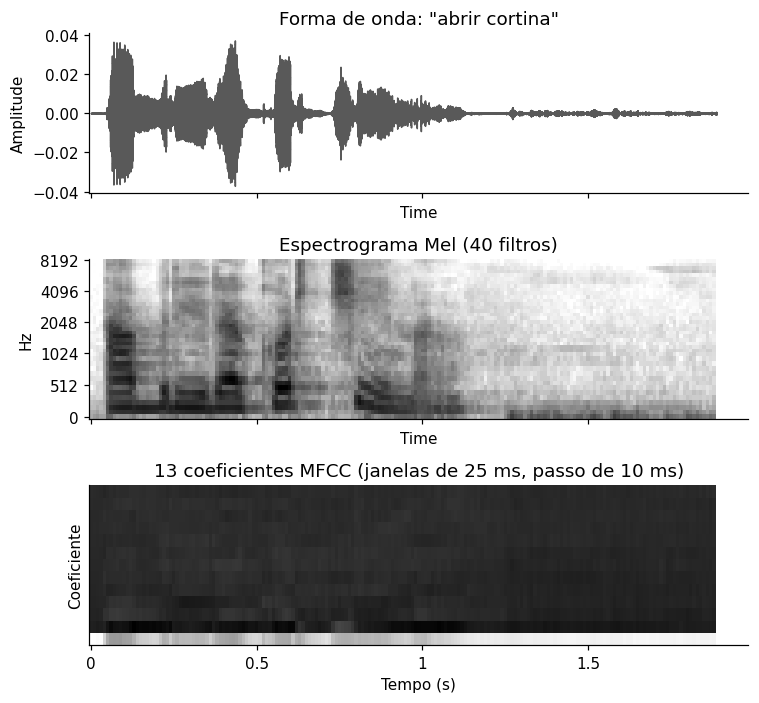

In [13]:
exemplo = cmd.sort_values("arquivo").iloc[0]
y, sr = librosa.load(os.path.join(AUDIO_DIR, exemplo["arquivo"]), sr=16000, mono=True)
y, _ = librosa.effects.trim(y, top_db=30)

fig, axs = plt.subplots(3, 1, figsize=(7, 6.5), sharex=True)
librosa.display.waveshow(y, sr=sr, ax=axs[0], color=COR)
axs[0].set_title(f"Forma de onda: \"{exemplo['rotulo'].replace('_', ' ')}\"")
axs[0].set_ylabel("Amplitude")

mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=160, n_mels=40), ref=np.max)
librosa.display.specshow(mel, sr=sr, hop_length=160, x_axis="time", y_axis="mel", ax=axs[1], cmap="gray_r")
axs[1].set_title("Espectrograma Mel (40 filtros)")

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=400, hop_length=160)
librosa.display.specshow(mfcc, sr=sr, hop_length=160, x_axis="time", ax=axs[2], cmap="gray_r")
axs[2].set_title("13 coeficientes MFCC (janelas de 25 ms, passo de 10 ms)")
axs[2].set_ylabel("Coeficiente"); axs[2].set_xlabel("Tempo (s)")
for ax in axs: ax.grid(False)
salvar("exemplo_mfcc")